# 04 — TabNet kurulum ve ilk deneme

**Sahibi:** Öğrenci 3 (TabNet & Comparative Analytics)

Bu notebook'un bu bölümü plan madde 9 / Adım 1-2'yi karşılar:
- `torch` ve `pytorch_tabnet` kurulumunun çalıştığını doğrula.
- 2.000 satırlık bir örneklemle 5 epoch'luk hızlı bir deneme yap.
- Kategorik kolonları `CAT_LEVELS`'tan türetilen sabit kodlarla 0..k-1 aralığına eşle
  (veriden değil, sözleşmeden türetilir ki test setinde görülmemiş bir kod çökme yaratmasın).


In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## Adım 1: Kurulum kontrolü

In [2]:
import torch
import pytorch_tabnet
from pytorch_tabnet.tab_model import TabNetClassifier
from importlib.metadata import version

print("torch         ", torch.__version__)
print("pytorch_tabnet", version("pytorch-tabnet"))
print("cuda var mı   ", torch.cuda.is_available(), "(CPU sürümüyle False beklenir)")

torch          2.14.1+cpu
pytorch_tabnet 4.1.0
cuda var mı    False (CPU sürümüyle False beklenir)


## Adım 2: Kategorik hazırlık

`cat_idxs` ve `cat_dims`, veriden değil `CAT_LEVELS` sözleşmesinden hesaplanır.
Sayısal kolonlar `make_preprocessor("tabnet")` ile ölçeklenir, kategorikler bu
hücrede 0..k-1 aralığına eşlenir (`make_preprocessor("tabnet")` kodları ham
bırakır, TabNet embedding'i 0'dan başlayan ardışık kod bekler).

In [3]:
from src.config import CAT_COLS, CAT_LEVELS, FEATURES, NUM_COLS
from src.data import load_split, to_xy
from src.features import make_preprocessor

CODE_MAPS = {col: {code: i for i, code in enumerate(levels)} for col, levels in CAT_LEVELS.items()}


def encode_categoricals(X):
    """Map each categorical column's raw codes to 0..k-1 using CAT_LEVELS."""
    X = X.copy()
    for col in CAT_COLS:
        X[col] = X[col].map(CODE_MAPS[col]).astype("int64")
    return X


cat_idxs = [FEATURES.index(col) for col in CAT_COLS]
cat_dims = [len(CAT_LEVELS[col]) for col in CAT_COLS]
list(zip(CAT_COLS, cat_idxs, cat_dims))

[('SEX', 1, 2),
 ('EDUCATION', 2, 7),
 ('MARRIAGE', 3, 4),
 ('PAY_0', 5, 11),
 ('PAY_2', 6, 11),
 ('PAY_3', 7, 11),
 ('PAY_4', 8, 11),
 ('PAY_5', 9, 11),
 ('PAY_6', 10, 11)]

## Adım 3: 2.000 satırlık hızlı deneme (5 epoch)

In [4]:
from src.config import SEED

VARIANT = "v0"  # Öğrenci 1'in clean_* dosyaları gelince "clean" olacak

train_full = load_split("train", VARIANT)
sample = train_full.sample(n=2000, random_state=SEED)
X_sample, y_sample = to_xy(sample)

preproc = make_preprocessor("tabnet")
X_scaled = preproc.fit_transform(X_sample)
X_scaled = encode_categoricals(X_scaled)
X_scaled = X_scaled[FEATURES].to_numpy(dtype="float32")
y_arr = y_sample.to_numpy()

X_scaled.shape, y_arr.shape

((2000, 23), (2000,))

In [5]:
clf = TabNetClassifier(
    cat_idxs=cat_idxs,
    cat_dims=cat_dims,
    cat_emb_dim=2,
    n_d=8,
    n_a=8,
    n_steps=3,
    gamma=1.3,
    seed=SEED,
    verbose=1,
)
clf.fit(
    X_scaled,
    y_arr,
    max_epochs=5,
    batch_size=256,
    virtual_batch_size=64,
)
print("Hızlı deneme tamamlandı, TabNet kurulumu çalışıyor.")

epoch 0  | loss: 0.64045 |  0:00:00s
epoch 1  | loss: 0.55545 |  0:00:00s


epoch 2  | loss: 0.52433 |  0:00:00s
epoch 3  | loss: 0.51859 |  0:00:00s


epoch 4  | loss: 0.49852 |  0:00:00s
Hızlı deneme tamamlandı, TabNet kurulumu çalışıyor.


## Adım 3: Grid tuning (Gün 2-4)

Taranan parametreler:
- `n_d = n_a` ∈ {8, 16, 32}
- `n_steps` ∈ {3, 5}
- `gamma` ∈ {1.3, 1.5}
- `mask_type` ∈ {sparsemax, entmax}
- `lambda_sparse` ∈ {1e-4, 1e-3}

48 kombinasyon fazla olacağından iki aşamalı yapılır:
1. **Aşama 1 (12 koşum):** `mask_type="sparsemax"`, `lambda_sparse=1e-3` sabit, `n_d/n_a × n_steps × gamma` taranır.
2. **Aşama 2 (8 koşum):** Aşama 1'in en iyi 2 konfigürasyonunda `mask_type × lambda_sparse` (2×2) taranır.

Seçim kriteri: validasyon AUC'si (erken durdurma da AUC'yi izler). Ayarlar: `max_epochs=100`,
`patience=20`, `batch_size=1024`, `virtual_batch_size=128`.

In [6]:
train_df = load_split("train", VARIANT)
val_df = load_split("val", VARIANT)
X_train_raw, y_train = to_xy(train_df)
X_val_raw, y_val = to_xy(val_df)

preproc = make_preprocessor("tabnet")
X_train = encode_categoricals(preproc.fit_transform(X_train_raw))[FEATURES].to_numpy(dtype="float32")
X_val = encode_categoricals(preproc.transform(X_val_raw))[FEATURES].to_numpy(dtype="float32")
y_train = y_train.to_numpy()
y_val = y_val.to_numpy()

X_train.shape, X_val.shape

((20975, 23), (4495, 23))

In [7]:
import time

import numpy as np
import pandas as pd


def run_tabnet(n_d, n_steps, gamma, mask_type, lambda_sparse):
    """Train one TabNet config, return its best validation AUC/logloss and timing."""
    start = time.time()
    clf = TabNetClassifier(
        cat_idxs=cat_idxs,
        cat_dims=cat_dims,
        cat_emb_dim=2,
        n_d=n_d,
        n_a=n_d,
        n_steps=n_steps,
        gamma=gamma,
        mask_type=mask_type,
        lambda_sparse=lambda_sparse,
        seed=SEED,
        verbose=0,
    )
    clf.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        eval_name=["val"],
        eval_metric=["auc", "logloss"],
        max_epochs=100,
        patience=20,
        batch_size=1024,
        virtual_batch_size=128,
    )
    elapsed = time.time() - start
    best_epoch = int(np.argmax(clf.history["val_auc"]))
    return {
        "n_d": n_d,
        "n_a": n_d,
        "n_steps": n_steps,
        "gamma": gamma,
        "mask_type": mask_type,
        "lambda_sparse": lambda_sparse,
        "val_auc": clf.history["val_auc"][best_epoch],
        "val_logloss": clf.history["val_logloss"][best_epoch],
        "epochs_trained": len(clf.history["val_auc"]),
        "train_seconds": round(elapsed, 1),
    }

### Aşama 1: `n_d/n_a × n_steps × gamma` (12 koşum, mask/lambda sabit)

In [8]:
import itertools

FIXED_MASK_TYPE = "sparsemax"
FIXED_LAMBDA_SPARSE = 1e-3

stage1_grid = list(itertools.product([8, 16, 32], [3, 5], [1.3, 1.5]))
stage1_results = []
for i, (n_d, n_steps, gamma) in enumerate(stage1_grid, start=1):
    print(f"[Aşama 1] {i}/{len(stage1_grid)}  n_d=n_a={n_d} n_steps={n_steps} gamma={gamma}")
    row = run_tabnet(n_d, n_steps, gamma, FIXED_MASK_TYPE, FIXED_LAMBDA_SPARSE)
    row["stage"] = 1
    stage1_results.append(row)
    print("  val_auc =", round(row["val_auc"], 4), " epochs =", row["epochs_trained"])

stage1_df = pd.DataFrame(stage1_results).sort_values("val_auc", ascending=False)
stage1_df

[Aşama 1] 1/12  n_d=n_a=8 n_steps=3 gamma=1.3



Early stopping occurred at epoch 74 with best_epoch = 54 and best_val_logloss = 0.43212


  val_auc = 0.7801  epochs = 75
[Aşama 1] 2/12  n_d=n_a=8 n_steps=3 gamma=1.5



Early stopping occurred at epoch 70 with best_epoch = 50 and best_val_logloss = 0.43807


  val_auc = 0.771  epochs = 71
[Aşama 1] 3/12  n_d=n_a=8 n_steps=5 gamma=1.3


...


Early stopping occurred at epoch 54 with best_epoch = 34 and best_val_logloss = 0.43729


  val_auc = 0.7717  epochs = 55
[Aşama 1] 12/12  n_d=n_a=32 n_steps=5 gamma=1.5



Early stopping occurred at epoch 61 with best_epoch = 41 and best_val_logloss = 0.43984


  val_auc = 0.7681  epochs = 62


,n_d,n_a,n_steps,gamma,mask_type,lambda_sparse,val_auc,val_logloss,epochs_trained,train_seconds,stage
0,8,8,3,1.3,sparsemax,0.001,0.780148,0.432118,75,77.1,1
5,16,16,3,1.5,sparsemax,0.001,0.778712,0.434481,49,52.6,1
8,32,32,3,1.3,sparsemax,0.001,0.777008,0.435760,48,62.2,1
4,16,16,3,1.3,sparsemax,0.001,0.775547,0.438140,64,68.9,1
9,32,32,3,1.5,sparsemax,0.001,0.774172,0.435883,77,99.6,1
10,32,32,5,1.3,sparsemax,0.001,0.771658,0.437751,55,107.6,1
1,8,8,3,1.5,sparsemax,0.001,0.771010,0.438068,71,73.0,1
7,16,16,5,1.5,sparsemax,0.001,0.769731,0.437589,84,129.7,1
11,32,32,5,1.5,sparsemax,0.001,0.768081,0.440161,62,122.9,1
6,16,16,5,1.3,sparsemax,0.001,0.766425,0.439541,45,70.4,1


### Aşama 2: en iyi 2 konfigürasyonda `mask_type × lambda_sparse` (2 taban × 4 kombinasyon = 8; sparsemax/1e-3 olan ikisi Aşama 1'den tekrar kullanılır, 6 yeni koşum yapılır)

In [9]:
top2 = stage1_df.head(2)[["n_d", "n_steps", "gamma"]].to_dict("records")

stage2_results = []
mask_lambda_grid = list(itertools.product(["sparsemax", "entmax"], [1e-4, 1e-3]))
for base in top2:
    for mask_type, lambda_sparse in mask_lambda_grid:
        if mask_type == FIXED_MASK_TYPE and lambda_sparse == FIXED_LAMBDA_SPARSE:
            continue  # already have this one from stage 1
        print(f"[Aşama 2] base={base} mask_type={mask_type} lambda_sparse={lambda_sparse}")
        row = run_tabnet(base["n_d"], base["n_steps"], base["gamma"], mask_type, lambda_sparse)
        row["stage"] = 2
        stage2_results.append(row)
        print("  val_auc =", round(row["val_auc"], 4), " epochs =", row["epochs_trained"])

stage2_df = pd.DataFrame(stage2_results)
stage2_df

[Aşama 2] base={'n_d': 8, 'n_steps': 3, 'gamma': 1.3} mask_type=sparsemax lambda_sparse=0.0001



Early stopping occurred at epoch 40 with best_epoch = 20 and best_val_logloss = 0.43722


  val_auc = 0.7713  epochs = 41
[Aşama 2] base={'n_d': 8, 'n_steps': 3, 'gamma': 1.3} mask_type=entmax lambda_sparse=0.0001



Early stopping occurred at epoch 44 with best_epoch = 24 and best_val_logloss = 0.43308


  val_auc = 0.7762  epochs = 45
[Aşama 2] base={'n_d': 8, 'n_steps': 3, 'gamma': 1.3} mask_type=entmax lambda_sparse=0.001


...


Early stopping occurred at epoch 38 with best_epoch = 18 and best_val_logloss = 0.43734


  val_auc = 0.7703  epochs = 39
[Aşama 2] base={'n_d': 16, 'n_steps': 3, 'gamma': 1.5} mask_type=entmax lambda_sparse=0.001



Early stopping occurred at epoch 40 with best_epoch = 20 and best_val_logloss = 0.43637


  val_auc = 0.7747  epochs = 41


,n_d,n_a,n_steps,gamma,mask_type,lambda_sparse,val_auc,val_logloss,epochs_trained,train_seconds,stage
0,8,8,3,1.3,sparsemax,0.0001,0.771336,0.437222,41,42.4,2
1,8,8,3,1.3,entmax,0.0001,0.776157,0.434184,45,46.9,2
2,8,8,3,1.3,entmax,0.0010,0.773971,0.436755,58,61.1,2
3,16,16,3,1.5,sparsemax,0.0001,0.777426,0.435797,65,71.8,2
4,16,16,3,1.5,entmax,0.0001,0.770254,0.443087,39,43.7,2
5,16,16,3,1.5,entmax,0.0010,0.774721,0.436408,41,45.6,2


In [10]:
from src.config import REPORTS_DIR

grid_df = pd.concat([stage1_df, stage2_df], ignore_index=True).sort_values(
    "val_auc", ascending=False
)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
grid_path = REPORTS_DIR / "tabnet_grid.csv"
grid_df.to_csv(grid_path, index=False)

best = grid_df.iloc[0]
print(f"En iyi config -> n_d=n_a={best.n_d} n_steps={best.n_steps} gamma={best.gamma} "
      f"mask_type={best.mask_type} lambda_sparse={best.lambda_sparse} "
      f"(val_auc={best.val_auc:.4f})")
grid_df

En iyi config -> n_d=n_a=8 n_steps=3 gamma=1.3 mask_type=sparsemax lambda_sparse=0.001 (val_auc=0.7801)


,n_d,n_a,n_steps,gamma,mask_type,lambda_sparse,val_auc,val_logloss,epochs_trained,train_seconds,stage
0,8,8,3,1.3,sparsemax,0.0010,0.780148,0.432118,75,77.1,1
1,16,16,3,1.5,sparsemax,0.0010,0.778712,0.434481,49,52.6,1
15,16,16,3,1.5,sparsemax,0.0001,0.777426,0.435797,65,71.8,2
2,32,32,3,1.3,sparsemax,0.0010,0.777008,0.435760,48,62.2,1
13,8,8,3,1.3,entmax,0.0001,0.776157,0.434184,45,46.9,2
3,16,16,3,1.3,sparsemax,0.0010,0.775547,0.438140,64,68.9,1
17,16,16,3,1.5,entmax,0.0010,0.774721,0.436408,41,45.6,2
4,32,32,3,1.5,sparsemax,0.0010,0.774172,0.435883,77,99.6,1
14,8,8,3,1.3,entmax,0.0010,0.773971,0.436755,58,61.1,2
5,32,32,5,1.3,sparsemax,0.0010,0.771658,0.437751,55,107.6,1


## Adım 4: Eğitim eğrileri (Gün 4)

En iyi konfigürasyonla eğitilen modelin `clf.history`'sinden train loss ve
validasyon AUC eğrileri çizilir → `figures/extra_tabnet_training.png`.

In [11]:
BEST = grid_df.iloc[0]

best_clf = TabNetClassifier(
    cat_idxs=cat_idxs,
    cat_dims=cat_dims,
    cat_emb_dim=2,
    n_d=int(BEST.n_d),
    n_a=int(BEST.n_a),
    n_steps=int(BEST.n_steps),
    gamma=float(BEST.gamma),
    mask_type=BEST.mask_type,
    lambda_sparse=float(BEST.lambda_sparse),
    seed=SEED,
    verbose=0,
)
best_clf.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_name=["val"],
    eval_metric=["auc", "logloss"],
    max_epochs=100,
    patience=20,
    batch_size=1024,
    virtual_batch_size=128,
)
print("En iyi config yeniden eğitildi, epoch sayısı:", len(best_clf.history["loss"]))


Early stopping occurred at epoch 74 with best_epoch = 54 and best_val_logloss = 0.43212


En iyi config yeniden eğitildi, epoch sayısı: 75


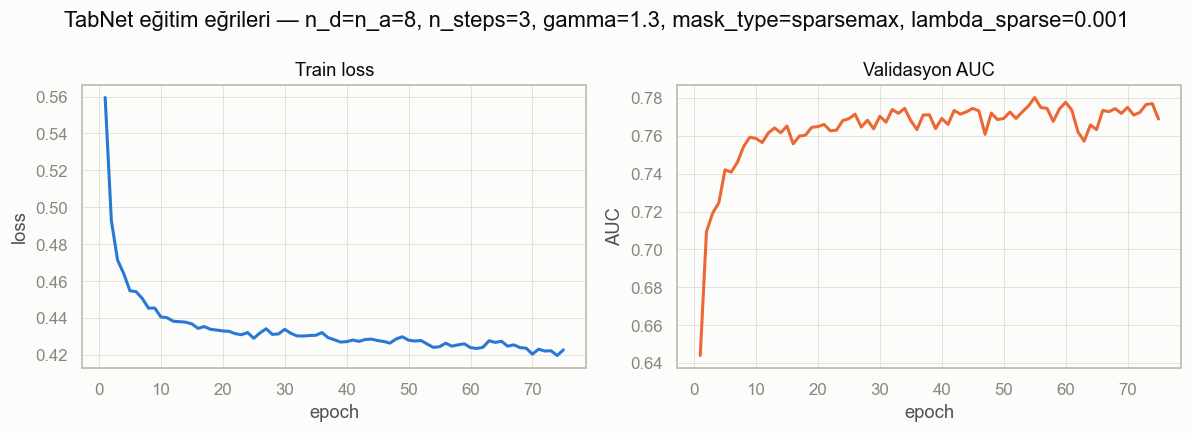

In [12]:
import matplotlib.pyplot as plt

from src.plots import SERIES, save_fig, set_style

set_style()
history = best_clf.history
epochs = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["loss"], color=SERIES[0])
axes[0].set(title="Train loss", xlabel="epoch", ylabel="loss")

axes[1].plot(epochs, history["val_auc"], color=SERIES[1])
axes[1].set(title="Validasyon AUC", xlabel="epoch", ylabel="AUC")

fig.suptitle(
    f"TabNet eğitim eğrileri — n_d=n_a={int(BEST.n_d)}, n_steps={int(BEST.n_steps)}, "
    f"gamma={BEST.gamma}, mask_type={BEST.mask_type}, lambda_sparse={BEST.lambda_sparse}"
)
fig.tight_layout()
save_fig(fig, "extra_tabnet_training")
plt.show()

## Adım 5: Grafik altyapısı (`src/plots.py`)

`plot_roc_pr`, `plot_cm_grid`, `plot_importance_and_masks`, `plot_missingness`,
`plot_kde_grid`, `plot_corr_diff` fonksiyonları `src/plots.py`'ye eklendi.
Burada her biri, gerçek veriler (Ö1'in SMOTE/CTGAN/nan_mask dosyaları, Ö2'nin
LGBM importance'ı) henüz gelmediği için **dummy/placeholder** veriyle duman
testi (smoke test) olarak çalıştırılıyor; final notebook'ta (`05_evaluation_plots`)
gerçek verilerle yeniden çağrılacaklar.

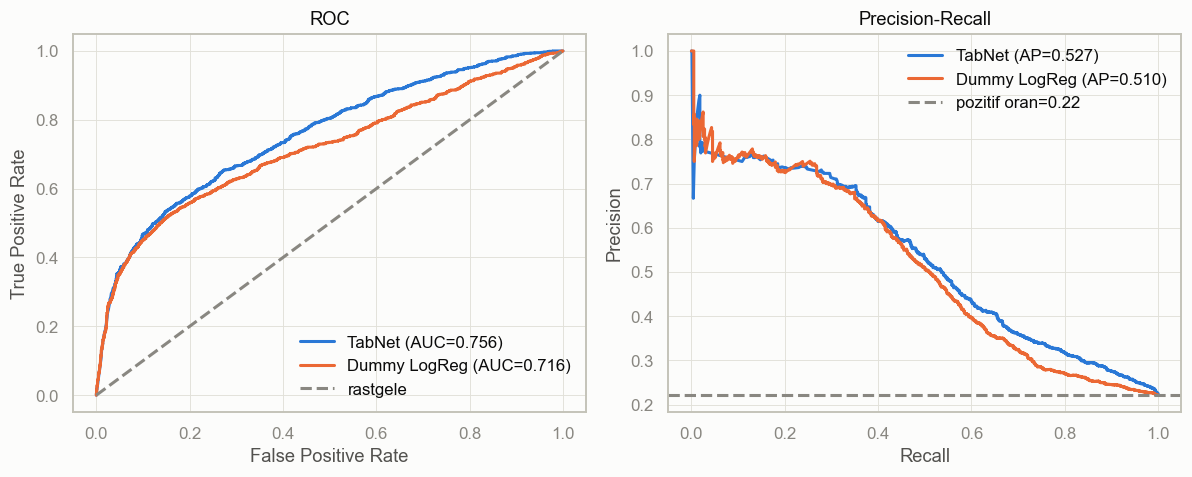

In [13]:
from src.metrics import pick_threshold
from src.plots import make_dummy_preds, plot_cm_grid, plot_roc_pr

dummy = make_dummy_preds(VARIANT)

test_df = load_split("test", VARIANT)
X_test_raw, y_test = to_xy(test_df)
X_test = encode_categoricals(preproc.transform(X_test_raw))[FEATURES].to_numpy(dtype="float32")
tabnet_score = best_clf.predict_proba(X_test)[:, 1]
tabnet_threshold = pick_threshold(y_val, best_clf.predict_proba(X_val)[:, 1])
tabnet_pred = (tabnet_score >= tabnet_threshold).astype(int)

models_score = {
    "TabNet": (y_test.to_numpy(), tabnet_score),
    "Dummy LogReg": (dummy["y_true"].to_numpy(), dummy["y_score"].to_numpy()),
}
fig = plot_roc_pr(models_score)
save_fig(fig, "extra_smoketest_roc_pr")
plt.show()

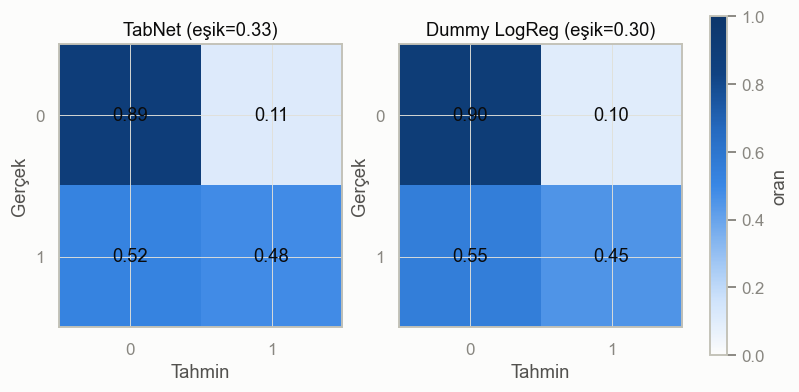

In [14]:
models_pred = {
    "TabNet": (y_test.to_numpy(), tabnet_pred, tabnet_threshold),
    "Dummy LogReg": (
        dummy["y_true"].to_numpy(),
        dummy["y_pred"].to_numpy(),
        dummy["threshold"].iloc[0],
    ),
}
fig = plot_cm_grid(models_pred)
save_fig(fig, "extra_smoketest_cm")
plt.show()

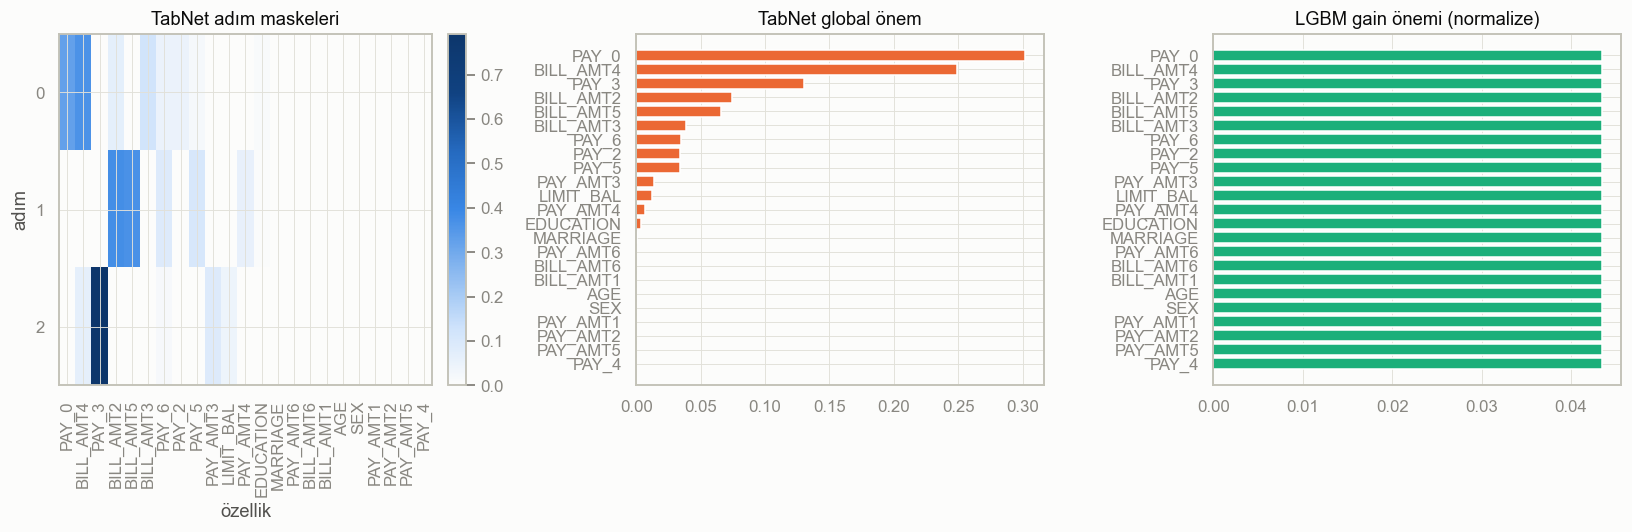

In [15]:
from src.plots import plot_importance_and_masks

explain_matrix, masks = best_clf.explain(X_test)
step_masks = np.stack([m.mean(axis=0) for m in masks.values()])

order = np.argsort(best_clf.feature_importances_)[::-1]
feature_order = [FEATURES[i] for i in order]
tabnet_importance = best_clf.feature_importances_[order]
step_masks_ordered = step_masks[:, order]
# Ö2'nin lgbm_importance.csv'si henüz yok; placeholder olarak eşit ağırlık kullanılır.
lgbm_importance_placeholder = np.ones(len(FEATURES))

fig = plot_importance_and_masks(
    step_masks_ordered, tabnet_importance, lgbm_importance_placeholder, feature_order
)
save_fig(fig, "extra_smoketest_importance_masks")
plt.show()

`plot_missingness`, `plot_kde_grid`, `plot_corr_diff` gerçek eksik veri / SMOTE /
CTGAN dosyalarını bekler (Ö1'in CP-A/CP-B çıktıları main'e merge olunca).
Henüz mevcut olmadıkları için burada küçük, rastgele üretilmiş **sentetik toy
veri** ile duman testi yapılıyor — sadece fonksiyonların çökmeden çalıştığını
doğrulamak için; `05_evaluation_plots.ipynb`'de gerçek verilerle değiştirilecek.

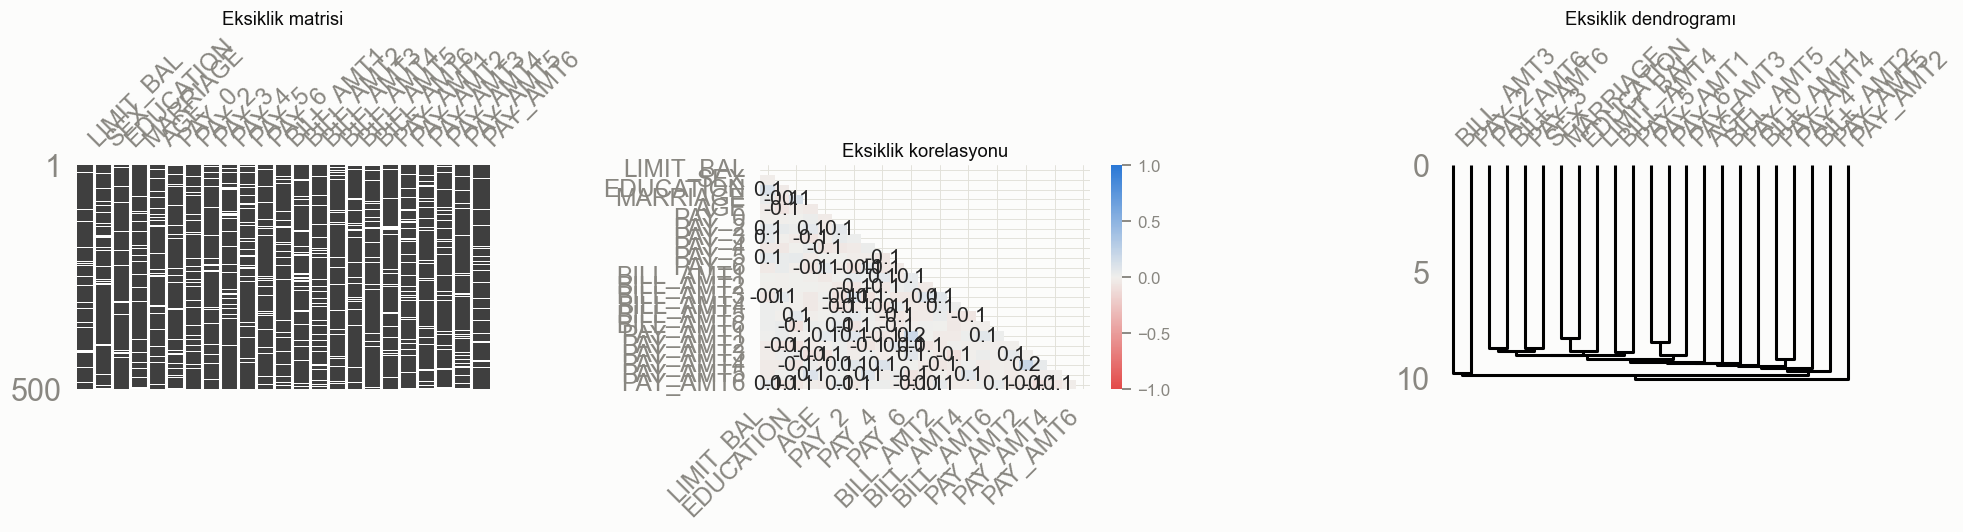

In [16]:
from src.plots import plot_corr_diff, plot_kde_grid, plot_missingness

rng = np.random.default_rng(SEED)
toy_cols = ["PAY_0", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1", "AGE", "PAY_2"]
toy_real = train_df[FEATURES].sample(n=500, random_state=SEED).reset_index(drop=True)
toy_real_nan = toy_real.mask(rng.random(toy_real.shape) < 0.1)

fig = plot_missingness(toy_real_nan)
save_fig(fig, "extra_smoketest_missingness")
plt.show()

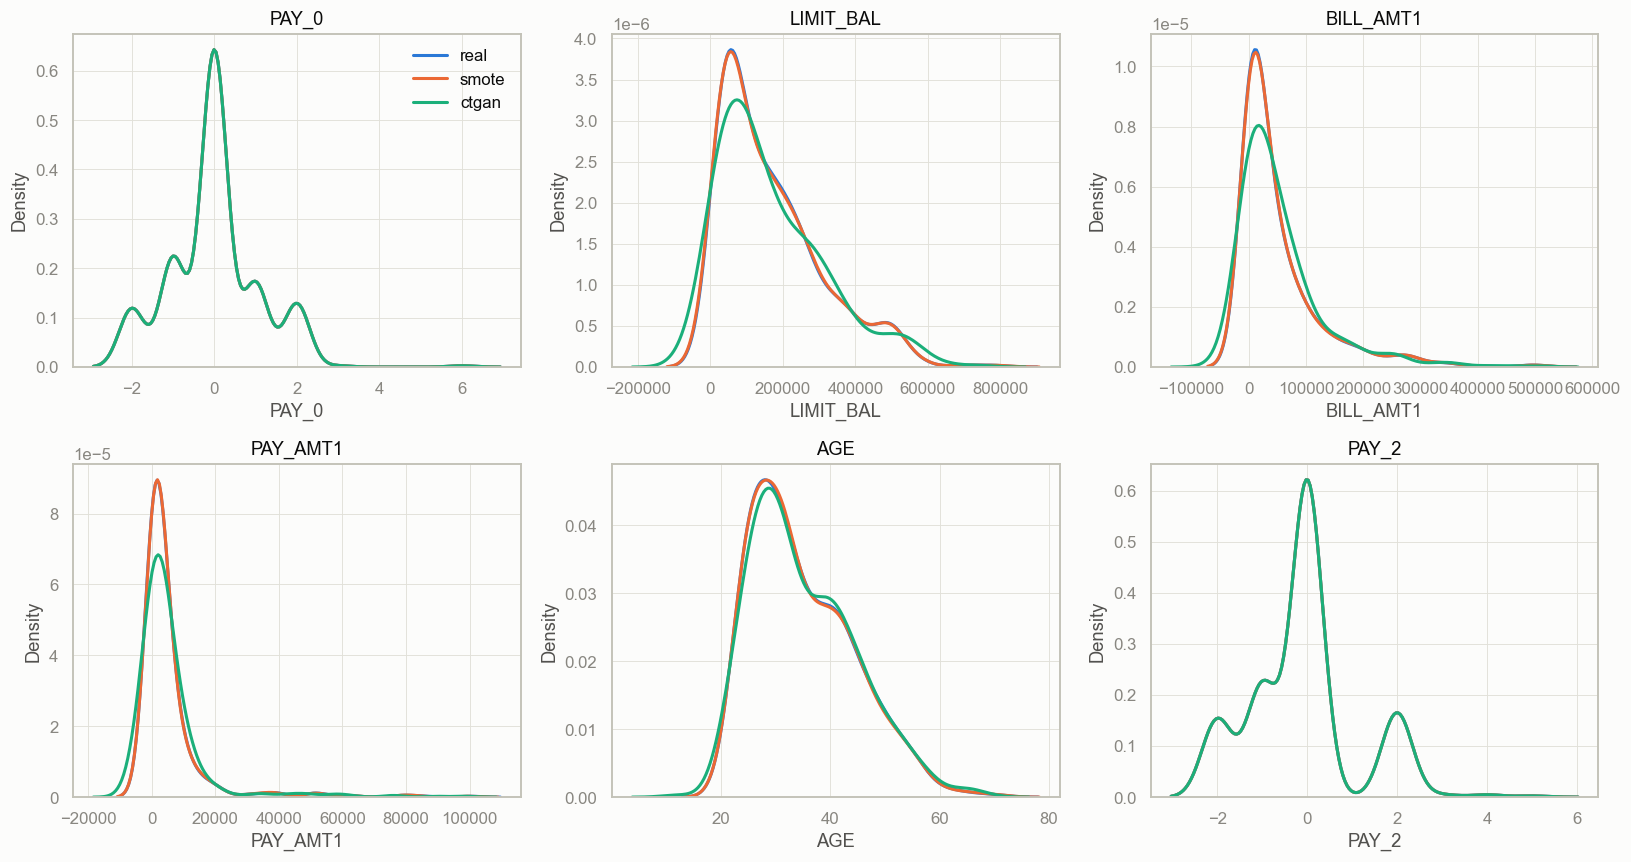

In [17]:
def jitter(df, scale=0.1):
    noisy = df.copy()
    for col in NUM_COLS:
        if col in noisy:
            noisy[col] = noisy[col] + rng.normal(0, noisy[col].std() * scale, len(noisy))
    return noisy


toy_smote = jitter(toy_real, scale=0.05)
toy_ctgan = jitter(toy_real, scale=0.3)

fig = plot_kde_grid(toy_real, toy_smote, toy_ctgan, toy_cols)
save_fig(fig, "extra_smoketest_kde")
plt.show()

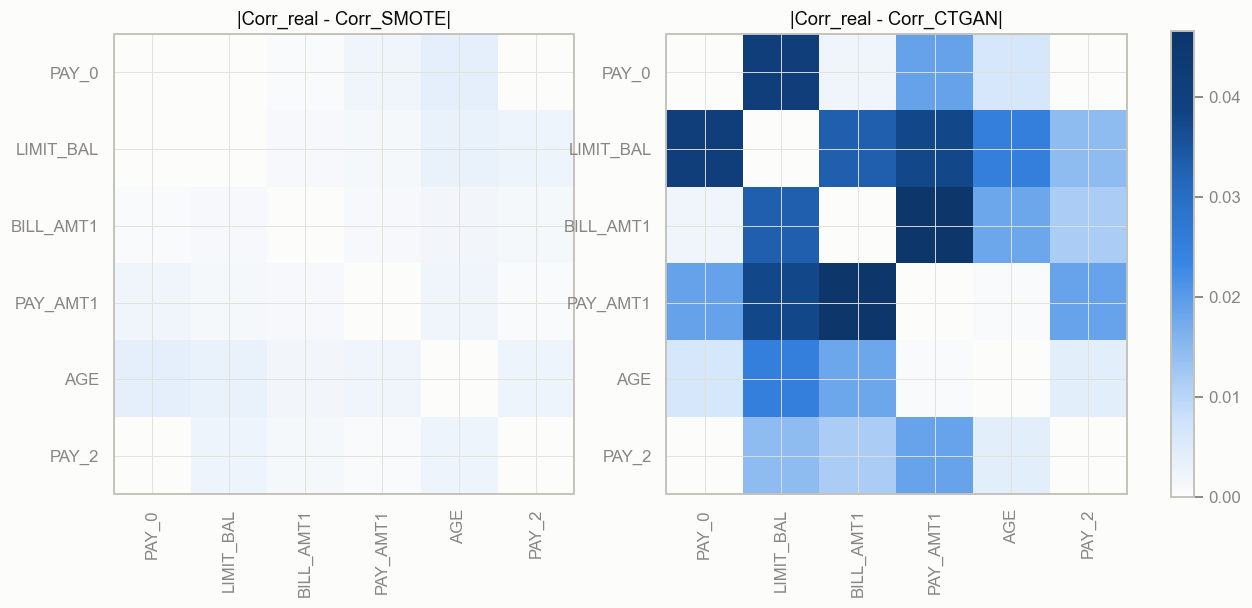

Adım 5 duman testi tamamlandı: tüm plots.py fonksiyonları hatasız çalışıyor.


In [18]:
corr_real = toy_real[toy_cols].corr()
corr_smote = toy_smote[toy_cols].corr()
corr_ctgan = toy_ctgan[toy_cols].corr()

fig = plot_corr_diff(corr_real, corr_smote, corr_ctgan)
save_fig(fig, "extra_smoketest_corr_diff")
plt.show()

print("Adım 5 duman testi tamamlandı: tüm plots.py fonksiyonları hatasız çalışıyor.")

## Adım 7 (v0 ön sürüm): tahminler ve önem dosyaları

Plan madde 9 / §2.2 dosya sözleşmesine göre `models/preds/tabnet.csv`'nin bir
**v0 sürümü Hafta 1 sonunda** hazır olmalı (Ö2'nin de kullanabilmesi için),
**final sürüm** CP-C'de `variant="clean"` ile üretilecek. Burada v0 sürümü
yazılıyor; Öğrenci 1'in `clean_*` verisi `main`'e merge olunca bu hücreler
`VARIANT = "clean"` ile tekrar çalıştırılacak.

In [19]:
from src.config import ID_COL
from src.metrics import evaluate, save_preds

preds_path = save_preds(
    "tabnet",
    row_id=test_df[ID_COL],
    y_true=y_test,
    y_score=tabnet_score,
    threshold=tabnet_threshold,
)
print("Kaydedildi:", preds_path)
evaluate(y_test, tabnet_score, tabnet_pred)

Kaydedildi: C:\Users\kdrgn\DataScienceProject\models\preds\tabnet.csv


{'macro_f1': 0.6929705784471434,
 'weighted_f1': 0.7930440391284571,
 'roc_auc': 0.7564858578607323,
 'pr_auc': 0.5271519303270753,
 'accuracy': 0.7979977753058954}

In [20]:
from src.config import IMPORTANCE_DIR

IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)

# step_masks (n_steps x 23, FEATURES sırasında) daha önce Adım 5'te hesaplandı
np.savez(IMPORTANCE_DIR / "tabnet_masks.npz", masks=step_masks, features=np.array(FEATURES))

tabnet_global = pd.DataFrame(
    {"feature": FEATURES, "importance": best_clf.feature_importances_}
).sort_values("importance", ascending=False)
tabnet_global.to_csv(IMPORTANCE_DIR / "tabnet_global.csv", index=False)

print("Kaydedildi:", IMPORTANCE_DIR / "tabnet_masks.npz", "ve tabnet_global.csv")
tabnet_global

Kaydedildi: C:\Users\kdrgn\DataScienceProject\models\importance\tabnet_masks.npz ve tabnet_global.csv


,feature,importance
5,PAY_0,3.016609e-01
14,BILL_AMT4,2.490803e-01
7,PAY_3,1.303232e-01
12,BILL_AMT2,7.434301e-02
15,BILL_AMT5,6.557349e-02
13,BILL_AMT3,3.845751e-02
10,PAY_6,3.487610e-02
6,PAY_2,3.436895e-02
9,PAY_5,3.388639e-02
19,PAY_AMT3,1.381412e-02
